# Name : Manthan Madankar
# Class : C2-B2
# Roll no : 16
# ML Practical 6

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,classification_report,confusion_matrix)

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input,Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

In [ ]:
df = pd.read_csv('seeds_new (1) - seeds_new (1).csv')
df.head()


,Area,Perimeter,Compactness,Length of kernel,Width of kernel,Asymmetry coefficient,Length of kernel groove,"Class (1, 2, 3)"
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1


In [ ]:
df.tail()

,Area,Perimeter,Compactness,Length of kernel,Width of kernel,Asymmetry coefficient,Length of kernel groove,"Class (1, 2, 3)"
205,12.19,13.20,0.8783,5.137,2.981,3.631,4.870,3
206,11.23,12.88,0.8511,5.140,2.795,4.325,5.003,3
207,13.20,13.66,0.8883,5.236,3.232,8.315,5.056,3
208,11.84,13.21,0.8521,5.175,2.836,3.598,5.044,3
209,12.30,13.34,0.8684,5.243,2.974,5.637,5.063,3


In [ ]:
print("\nDataset Shape:")
print(df.shape)
print("\nColumn Names:")
print(df.columns.tolist())
print("\nDataset Information:")
df.info()
print("\nStatistical Summary:")
print(df.describe())
print("\nMissing Values:")
print(df.isnull().sum())
print("\nNumber of Duplicate Rows:")
print(df.duplicated().sum())


Dataset Shape:
(210, 8)

Column Names:
['Area', 'Perimeter', 'Compactness', 'Length of kernel', 'Width of kernel', 'Asymmetry coefficient', 'Length of kernel groove', 'Class (1, 2, 3)']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 210 entries, 0 to 209
Data columns (total 8 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Area                     210 non-null    float64
 1   Perimeter                210 non-null    float64
 2   Compactness              210 non-null    float64
 3   Length of kernel         210 non-null    float64
 4   Width of kernel          210 non-null    float64
 5   Asymmetry coefficient    210 non-null    float64
 6   Length of kernel groove  210 non-null    float64
 7   Class (1, 2, 3)          210 non-null    int64  
dtypes: float64(7), int64(1)
memory usage: 13.3 KB

Statistical Summary:
             Area   Perimeter  ...  Length of kernel groove  Class (1, 2, 

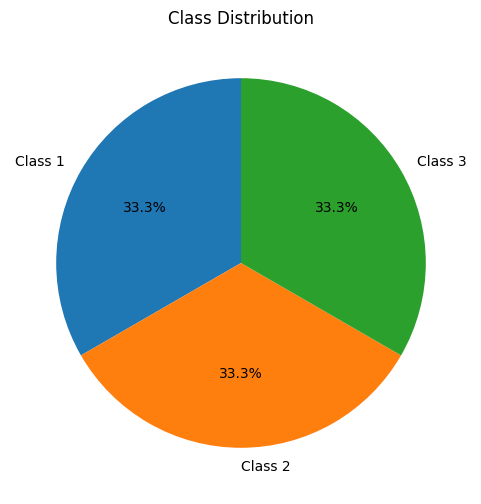

In [ ]:
class_counts=df['Class (1, 2, 3)'].value_counts().sort_index()
plt.figure(figsize=(6,6))
plt.pie(class_counts,labels=['Class 1','Class 2','Class 3'],autopct='%1.1f%%',startangle=90)
plt.title('Class Distribution')
plt.show()

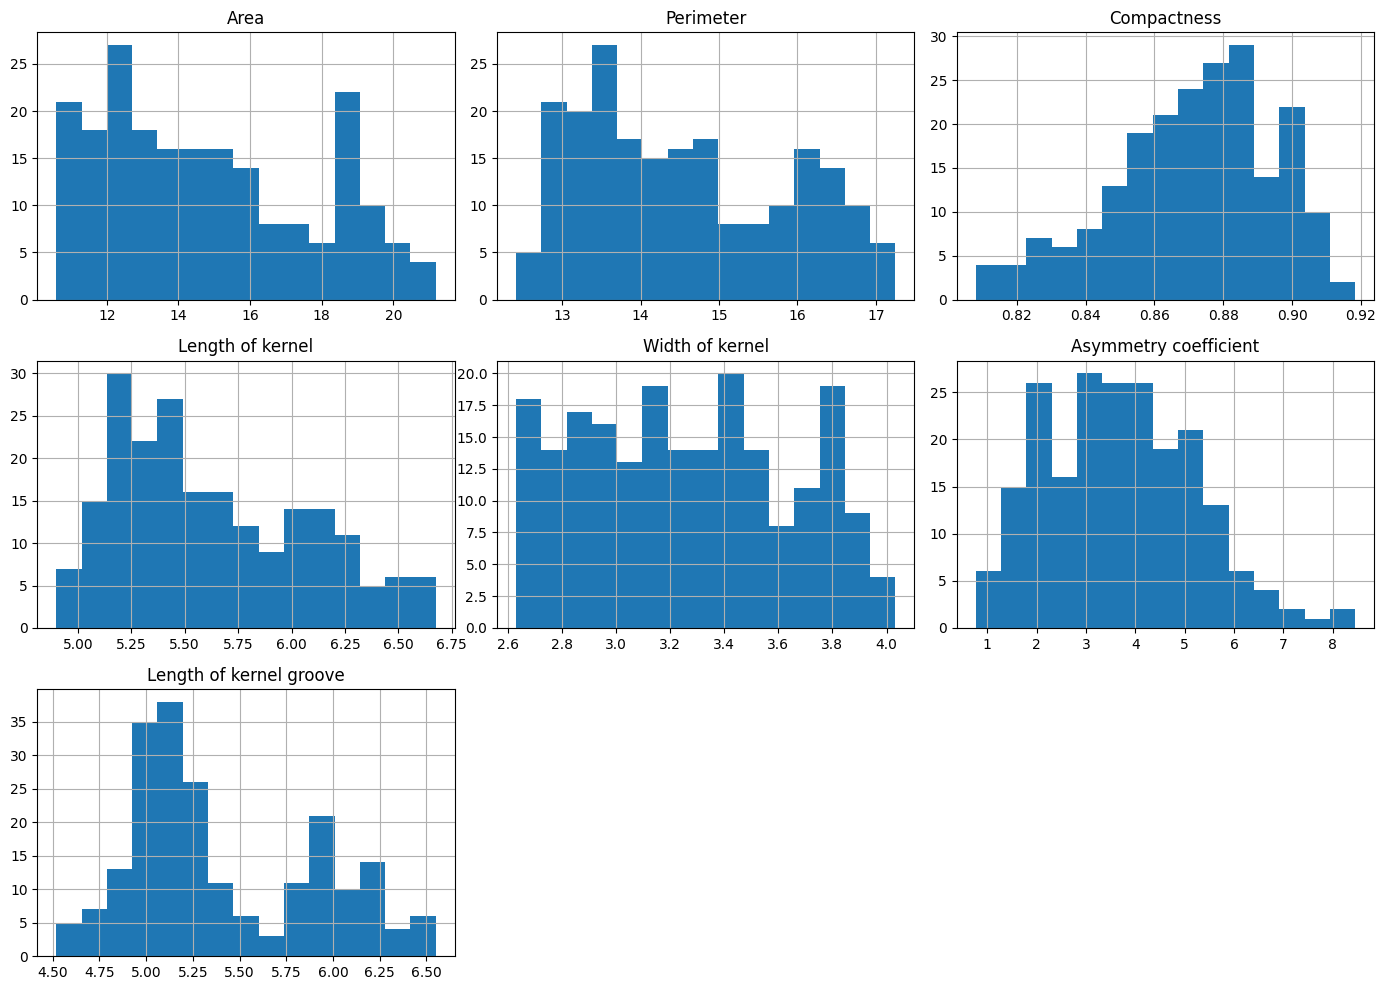

In [ ]:
df.drop('Class (1, 2, 3)',axis=1).hist(figsize=(14,10),bins=15)
plt.title('Distribution of input features')
plt.tight_layout()
plt.show()

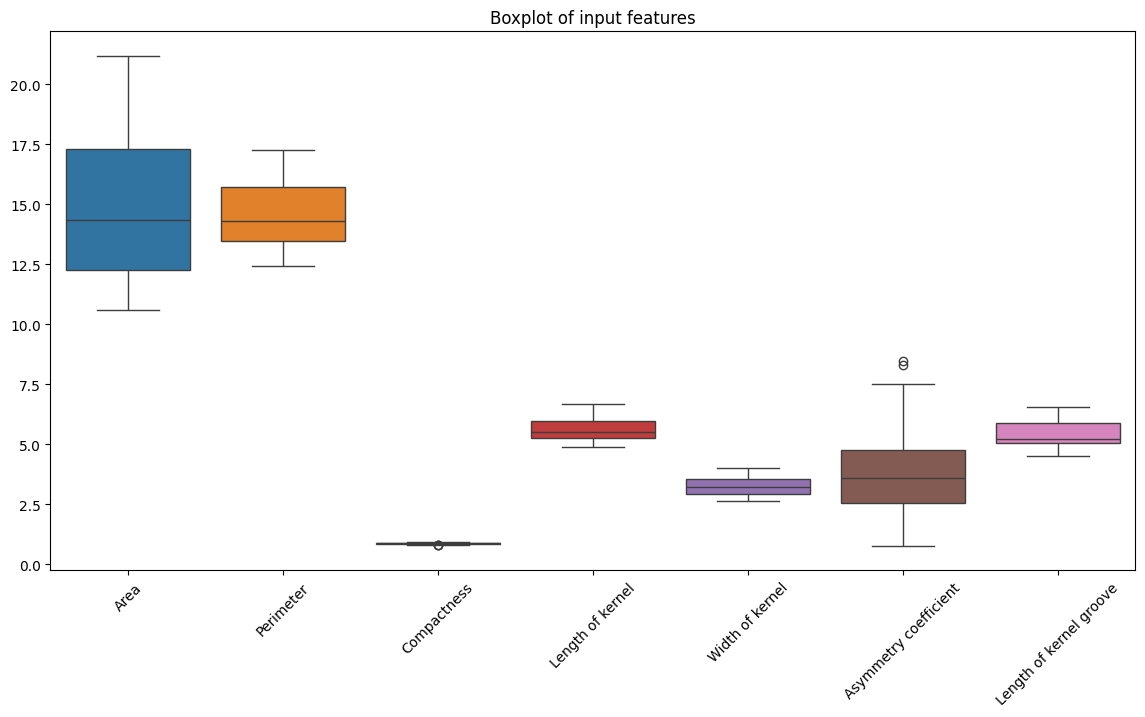

In [ ]:
plt.figure(figsize=(14,7))
sns.boxplot(data=df.drop('Class (1, 2, 3)',axis=1))
plt.title('Boxplot of input features')
plt.xticks(rotation=45)
plt.show()

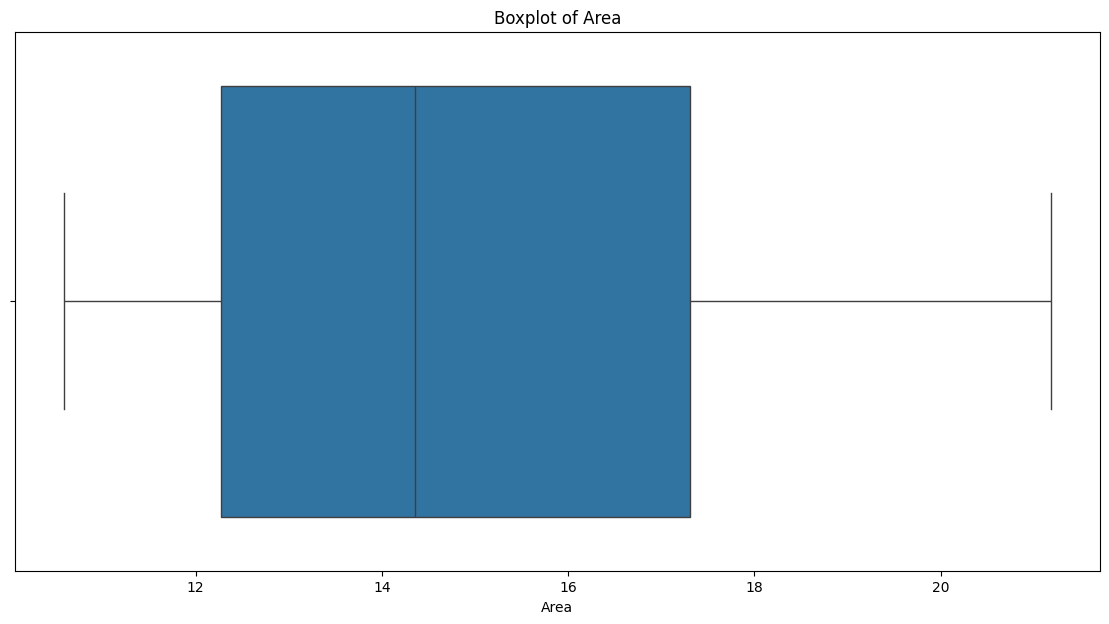

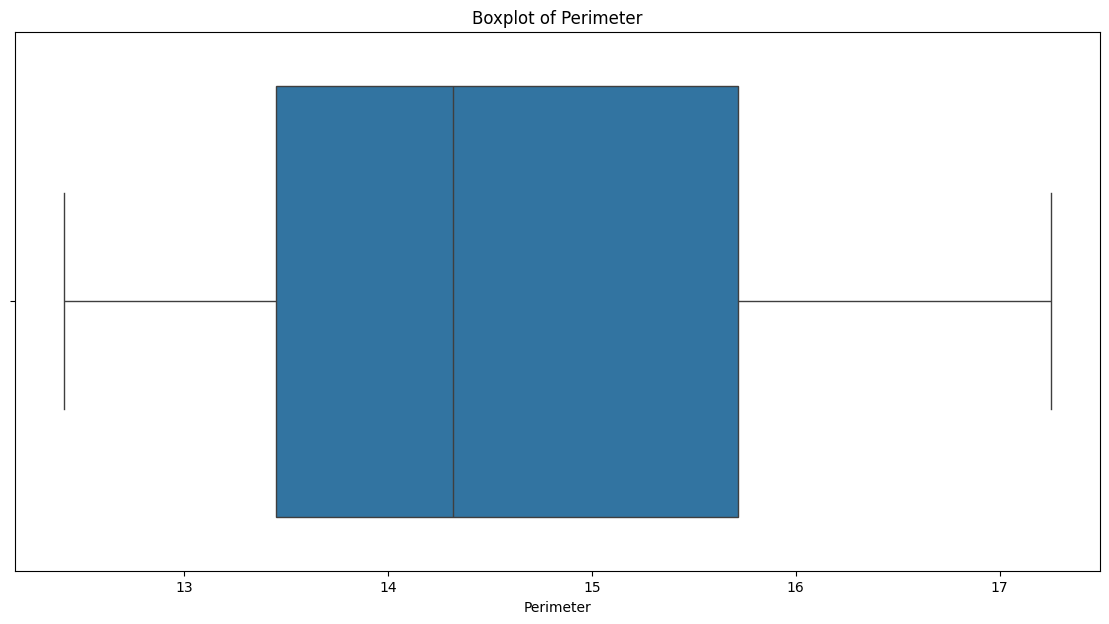

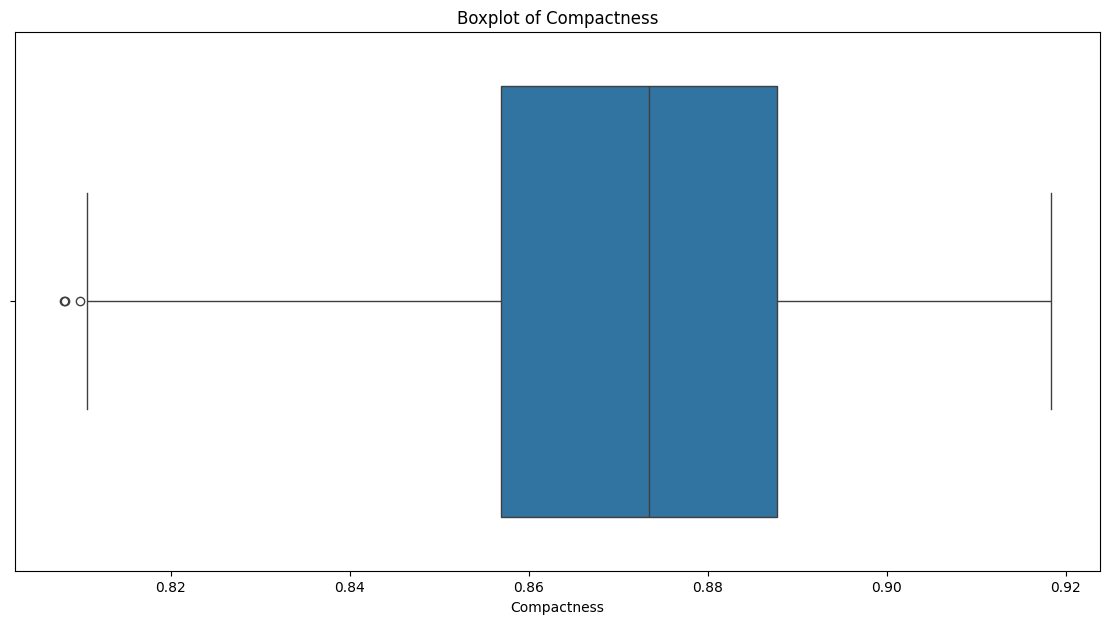

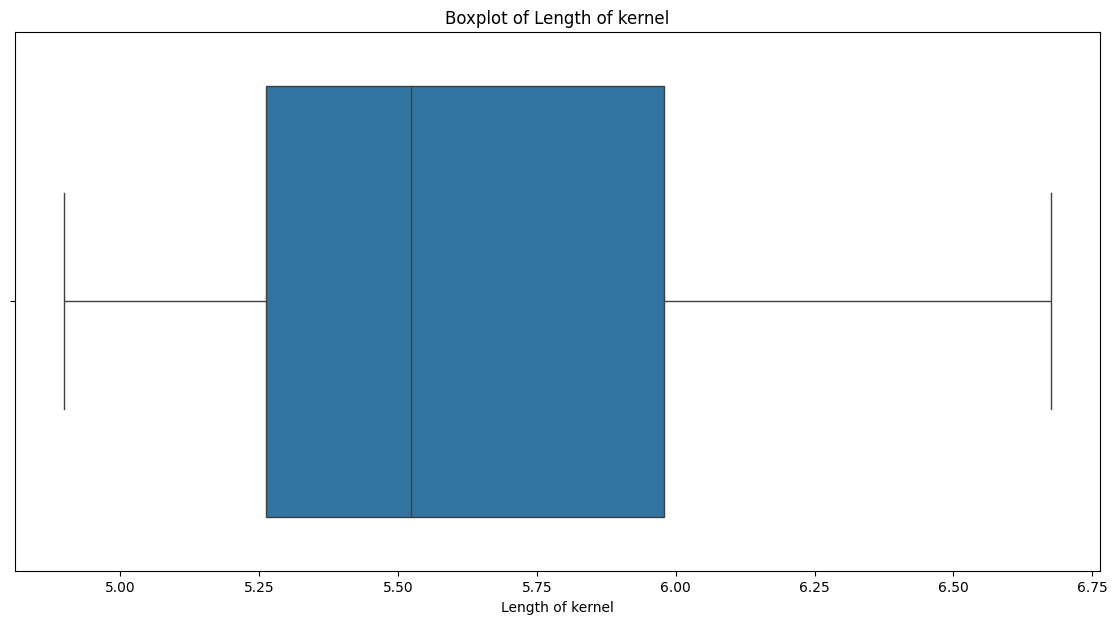

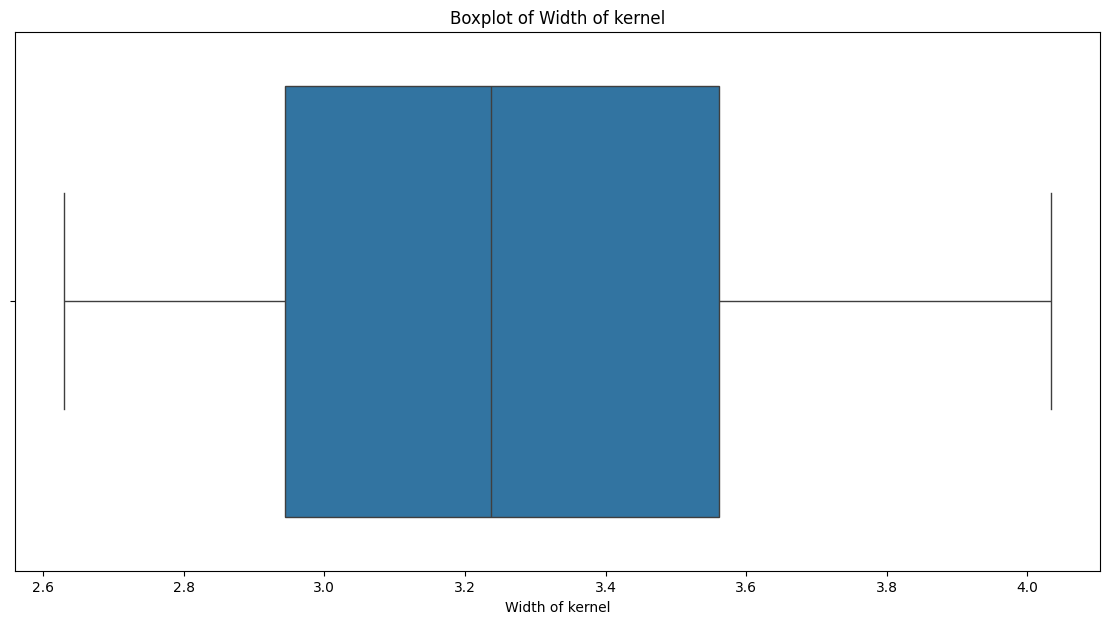

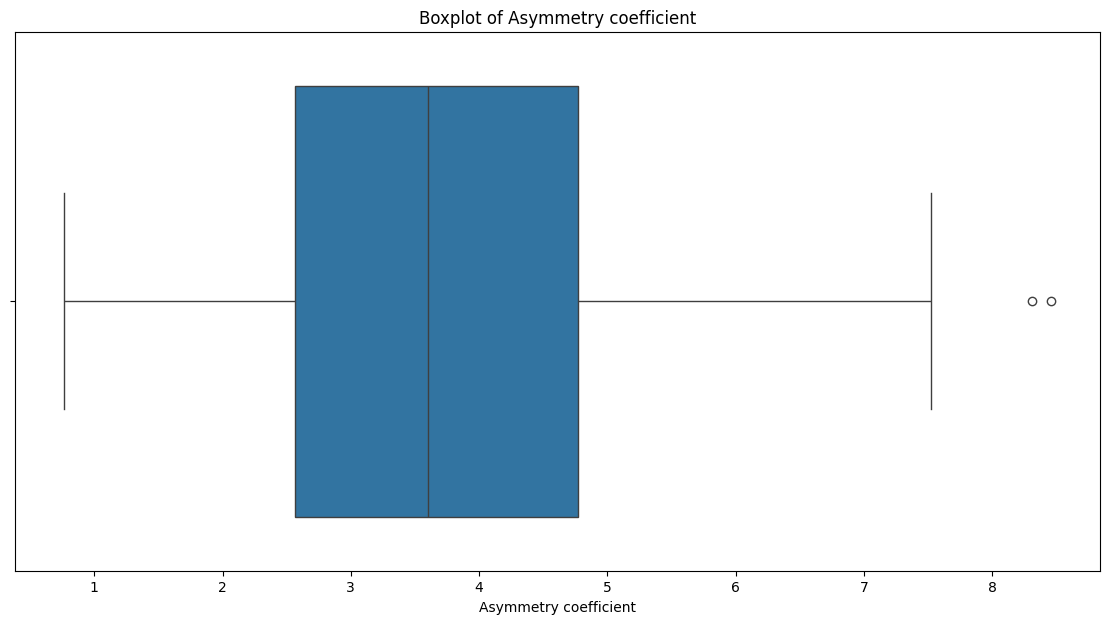

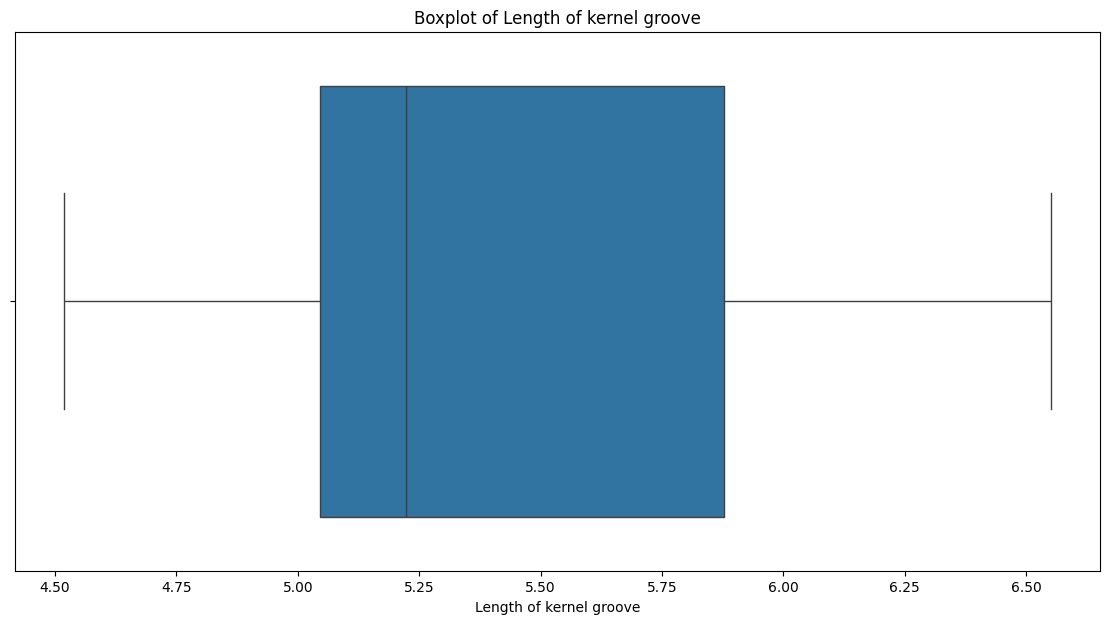

In [ ]:
features=df.drop('Class (1, 2, 3)',axis=1).columns
for feature in features:
    plt.figure(figsize=(14,7))
    sns.boxplot(x=df[feature])
    plt.title(f'Boxplot of {feature}')
    plt.xlabel(feature)
    plt.show()

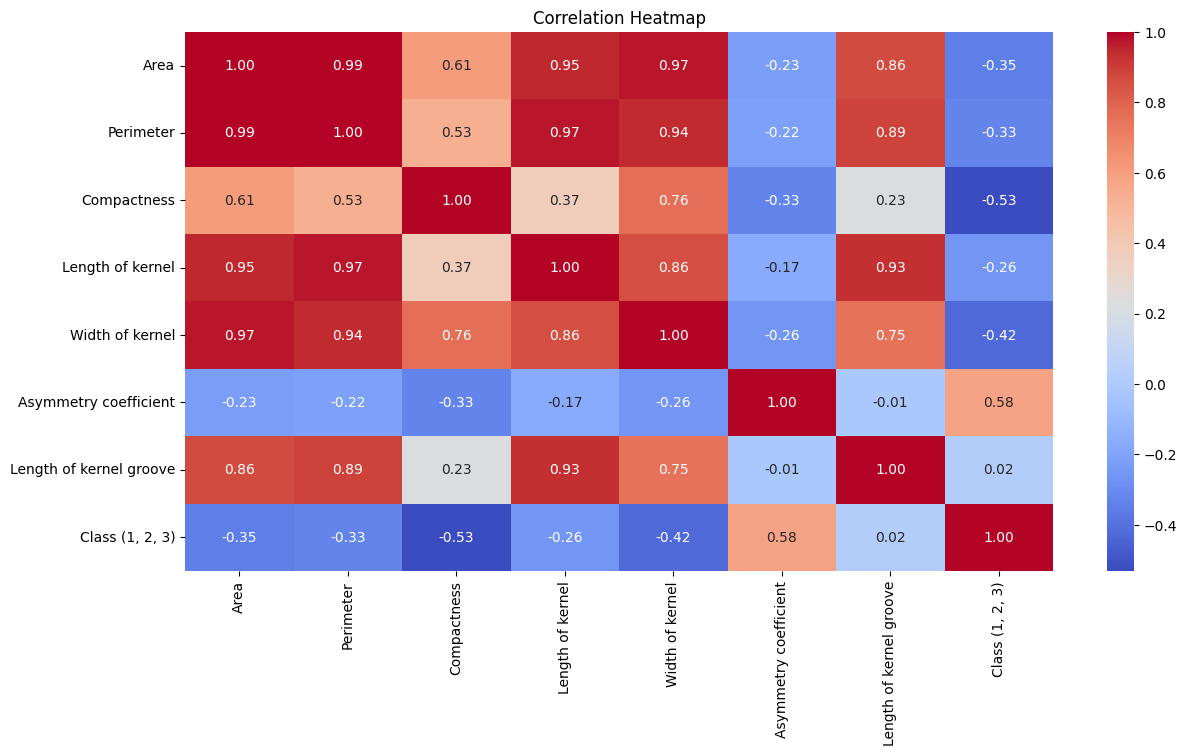

In [ ]:
plt.figure(figsize=(14,7))
correlation=df.corr()
sns.heatmap(correlation,annot=True,cmap='coolwarm',fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

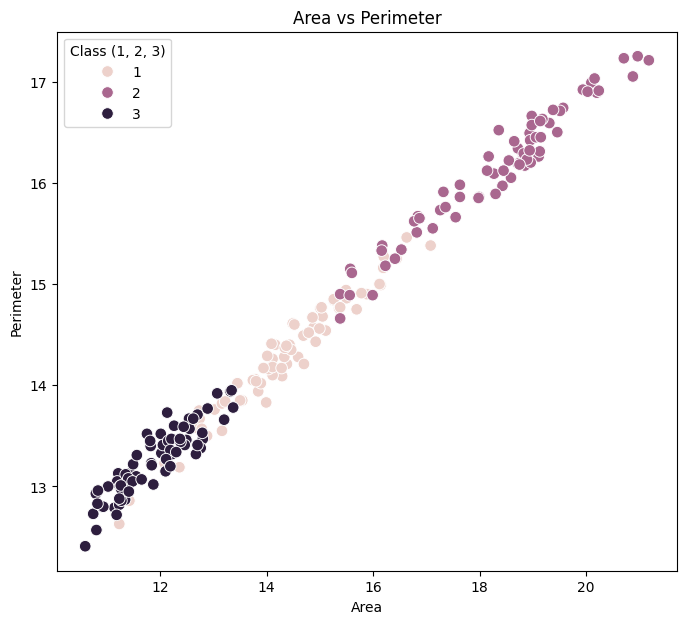

In [ ]:
plt.figure(figsize=(8,7))
sns.scatterplot(df,x='Area',y='Perimeter',hue='Class (1, 2, 3)',s=70)
plt.title('Area vs Perimeter')
plt.show()

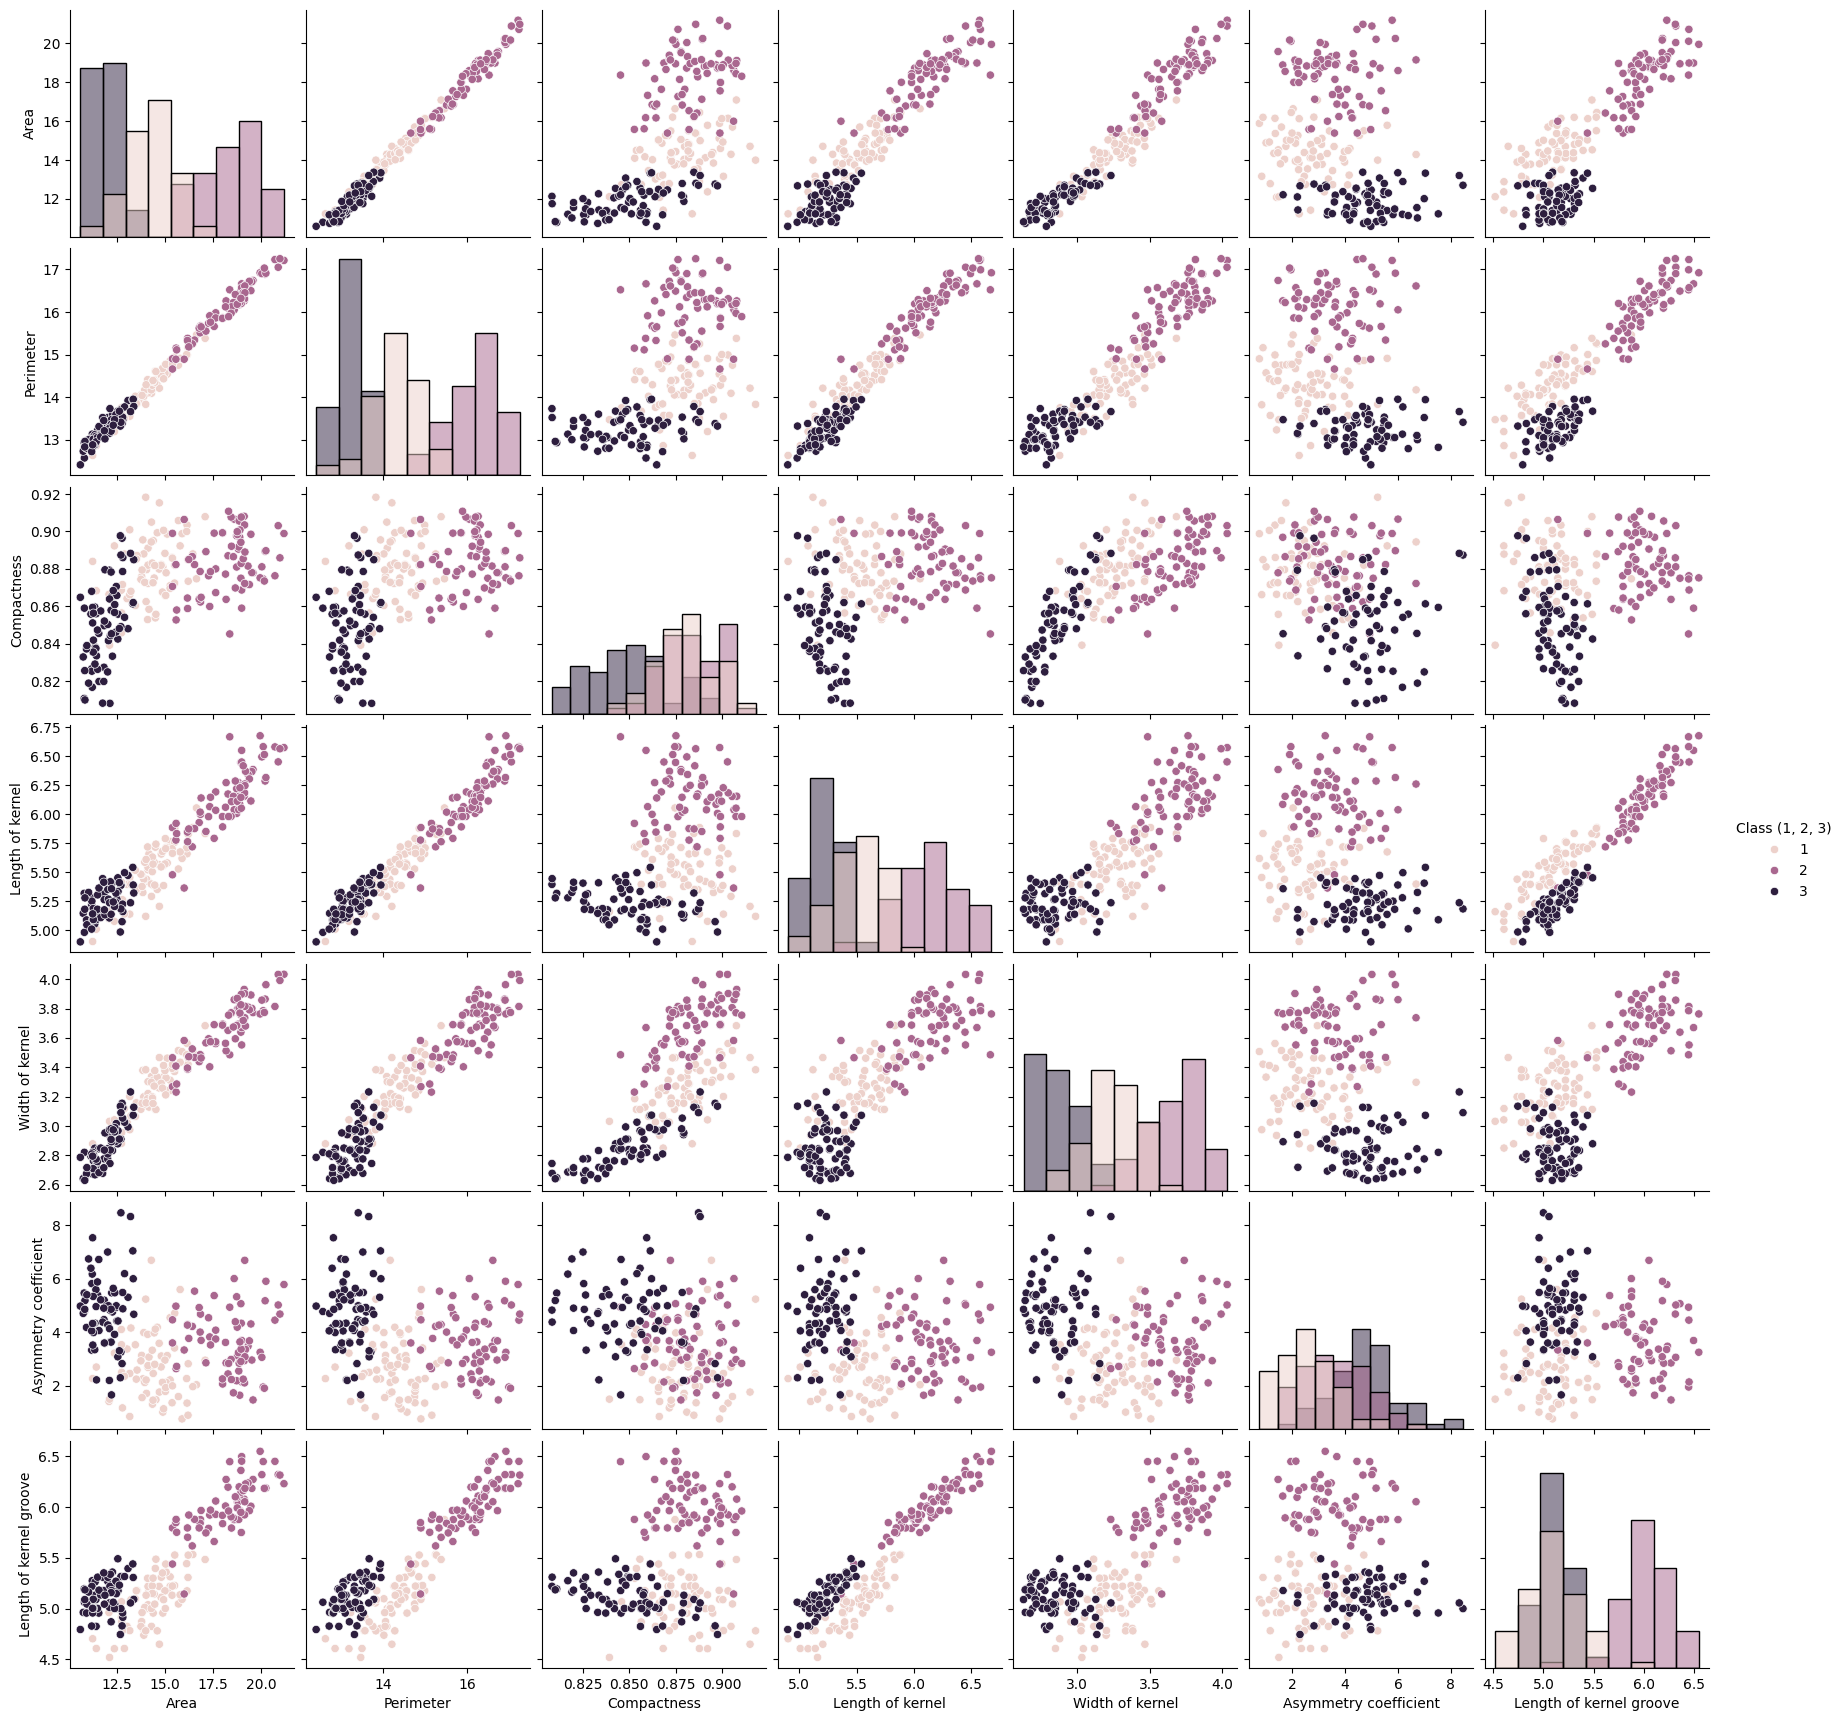

In [ ]:
sns.pairplot(df,hue='Class (1, 2, 3)',diag_kind='hist')
plt.show()

In [ ]:
X=df.drop('Class (1, 2, 3)',axis=1)
y_original=df['Class (1, 2, 3)']
print('Input shape:',X.shape)
print('Target shape:',y_original.shape)

Input shape: (210, 7)
Target shape: (210,)


In [ ]:
y=y_original-1
print('Original classes:')
print(sorted(y_original.unique()))
print('\nANN encoded classes:')
print(sorted(y.unique()))

Original classes:
[np.int64(1), np.int64(2), np.int64(3)]

ANN encoded classes:
[np.int64(0), np.int64(1), np.int64(2)]


In [ ]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
print('Training data shape:',X_train.shape[0])
print('Testing data shape:',X_test.shape[0])

Training data shape: 168
Testing data shape: 42


In [ ]:
scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)

In [ ]:
scaler.fit_transform(X_test)

array([[-0.13481356, -0.30885661,  1.63834475, -0.72108928,  0.28326462,
        -0.76430253, -1.20943602],
       [-0.86696115, -0.79265998, -1.079508  , -0.44412568, -1.01611436,
        -0.08296069, -0.1493714 ],
       [ 0.3031065 ,  0.49244271, -0.70339658,  0.66153059,  0.00779627,
        -0.80711315,  0.9685525 ],
       [-1.32882996, -1.4578896 , -0.42131302, -1.40250766, -1.05769449,
         0.74059948, -0.71763216],
       [ 1.23710786,  1.05184035,  1.89804073,  0.79121989,  1.36954545,
        -0.66416923,  1.14006393],
       [-0.46667485, -0.42224803, -0.31833013, -0.17155833, -0.40280748,
         2.38191499,  0.06140168],
       [ 2.15058173,  2.0799225 ,  0.78313902,  2.07492419,  1.98285233,
         0.67094153,  1.87157051],
       [ 0.37495276,  0.31101645,  1.0697001 ,  0.12079214,  0.53534414,
         1.33559449, -0.56678476],
       [ 1.65107916,  1.67171341,  0.42941519,  1.6418938 ,  1.48908831,
        -0.57346877,  1.60087175],
       [ 1.28842662,  1.2257

In [ ]:
print('First 5 samples:')
print(X_train_scaled[:5])

First 5 samples:
[[-1.17682401 -1.1750583  -1.02169157 -1.02785725 -1.35751947  1.43188942
  -0.82441016]
 [-0.87298429 -1.06714618  0.86676795 -1.26492983 -0.59897345 -0.3056117
  -1.63150367]
 [-0.12719589  0.01968295 -0.66917913  0.25096694 -0.40933695 -1.4432301
   0.1615857 ]
 [-1.29421662 -1.37546651 -0.66498255 -1.41310019 -1.26136575  1.7668294
  -0.72886004]
 [-0.58295547 -0.70486981  0.69890488 -0.90020279 -0.09149548  3.02743357
  -0.71462918]]


In [ ]:
model=Sequential([
    Input(shape=(7,)),
    Dense(16,activation='relu'),
    Dense(8,activation='relu'),
    Dense(3,activation='softmax')
])

In [ ]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 16)             │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 291 (1.14 KB)

 Trainable params: 291 (1.14 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model1=Sequential([
    Input(shape=(7,)),
    Dense(30,activation='relu'),
    Dense(3,activation='relu'),
    Dense(5,activation='softmax')
])

In [ ]:
model1.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_9 (Dense)                 │ (None, 30)             │           240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 3)              │            93 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 5)              │            20 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 353 (1.38 KB)

 Trainable params: 353 (1.38 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [ ]:
loss='sparse_categorical_crossentropy'
early_stop=EarlyStopping(monitor='val_loss',patience=10,restore_best_weights=True)

In [ ]:
history=model.fit(
    X_train_scaled,y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=16,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 3s 60ms/step - accuracy: 0.3582 - loss: 1.1842 - val_accuracy: 0.2353 - val_loss: 1.1597
Epoch 2/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.3657 - loss: 1.0952 - val_accuracy: 0.2647 - val_loss: 1.0935
Epoch 3/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.3731 - loss: 1.0378 - val_accuracy: 0.3824 - val_loss: 1.0498
Epoch 4/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.3806 - loss: 1.0002 - val_accuracy: 0.3824 - val_loss: 1.0139
Epoch 5/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.4328 - loss: 0.9650 - val_accuracy: 0.4412 - val_loss: 0.9783
Epoch 6/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.5149 - loss: 0.9293 - val_accuracy: 0.5882 - val_loss: 0.9398
Epoch 7/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.6343 - loss: 0.8925 - val_accuracy: 0.6765 - val_loss: 0.9007
Epoch 8/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.7313 - loss: 0.8540 - val_accuracy: 0.7353 - val_loss:

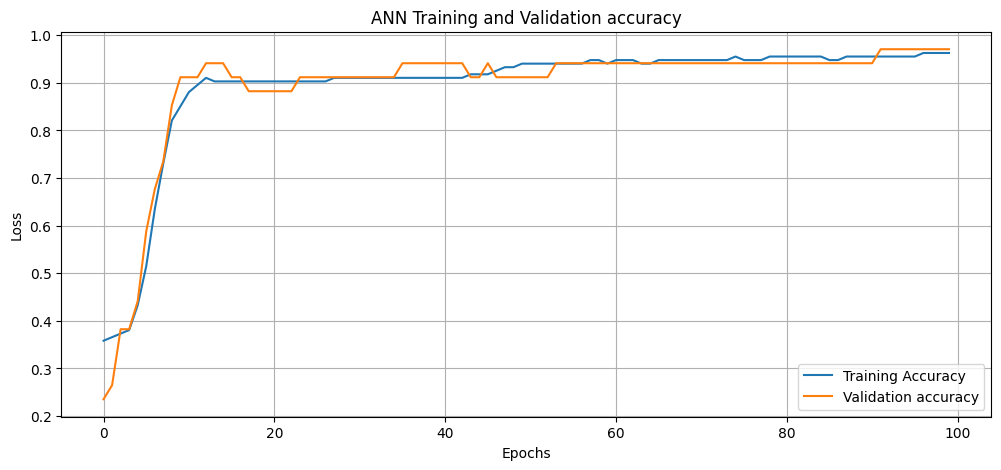

In [ ]:
plt.figure(figsize=(12,5))
plt.plot(history.history['accuracy'],label='Training Accuracy')
plt.plot(history.history['val_accuracy'],label='Validation accuracy')
plt.title('ANN Training and Validation accuracy')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

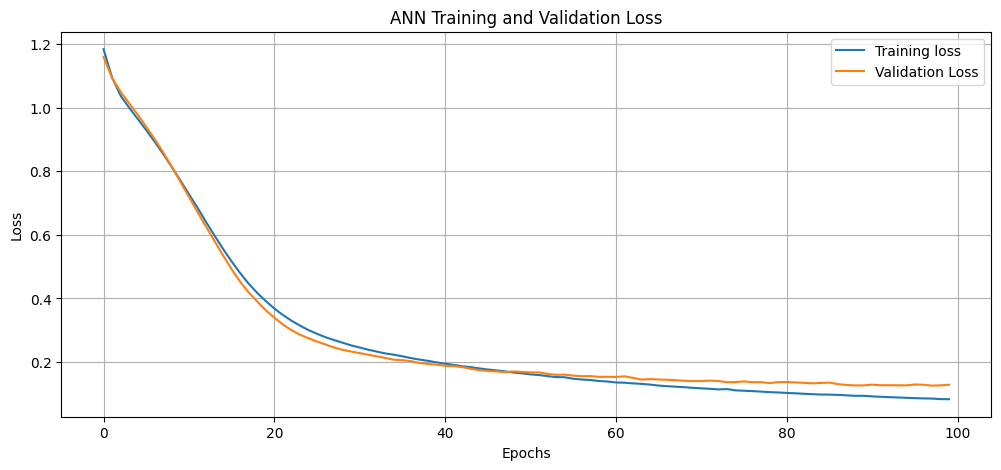

In [ ]:
plt.figure(figsize=(12,5))
plt.plot(history.history['loss'],label='Training loss')
plt.plot(history.history['val_loss'],label='Validation Loss')
plt.title('ANN Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
test_loss,test_accuracy=model.evaluate(X_test_scaled,y_test,verbose=1)
print('Test Loss:',test_loss)
print('Test Accuracy:',test_accuracy)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step - accuracy: 0.8571 - loss: 0.3258
Test Loss: 0.3257828950881958
Test Accuracy: 0.8571428656578064


In [ ]:
y_prob=model.predict(X_test_scaled,verbose=1)
print(y_prob[:5])

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step
[[9.9220496e-01 9.7369106e-04 6.8212827e-03]
 [9.0696596e-02 3.3980185e-05 9.0926945e-01]
 [8.0101633e-01 1.8816970e-01 1.0813932e-02]
 [1.5554698e-03 2.9881312e-07 9.9844432e-01]
 [1.2558646e-03 9.9874300e-01 1.2287219e-06]]


In [ ]:
y_pred=np.argmax(y_prob,axis=1)
print(y_pred[:10])

[0 2 0 2 1 2 1 1 1 1]


In [ ]:
y_pred_original=y_pred+1
y_test_original=y_test+1
print('Predicted classes:')
print(y_pred_original[:10])
print('\nActual classes:')
print(y_test_original[:10])

Predicted classes:
[1 3 1 3 2 3 2 2 2 2]

Actual classes:
2      1
167    3
137    2
175    3
130    2
141    3
114    2
51     1
84     2
110    2
Name: Class (1, 2, 3), dtype: int64


In [ ]:
comparision=pd.DataFrame({'Actual':y_test_original.values,'Predicted':y_pred_original})
print(comparision.head(15))

    Actual  Predicted
0        1          1
1        3          3
2        2          1
3        3          3
4        2          2
5        3          3
6        2          2
7        1          2
8        2          2
9        2          2
10       1          1
11       3          3
12       2          2
13       2          2
14       3          3


In [ ]:
accuracy=accuracy_score(y_test_original,y_pred_original)
precision=precision_score(y_test_original,y_pred_original,average='weighted')
recall=recall_score(y_test_original,y_pred_original,average='weighted')
f1=f1_score(y_test_original,y_pred_original,average='weighted')
print('Accuracy:',accuracy)
print('Precision:',precision)
print('Recall:',recall)
print('F1 Score:',f1)

Accuracy: 0.8571428571428571
Precision: 0.8625
Recall: 0.8571428571428571
F1 Score: 0.8500000000000001


In [ ]:
metrics=pd.DataFrame({'Metric':['Accuracy','Precision','Recall','F1 Score'],'Value':[accuracy,precision,recall,f1]})
class_report=classification_report(y_test_original,y_pred_original,target_names=['Class 1','Class 2','Class 3'])
print('Classification Report:')
print(class_report)

Classification Report:
              precision    recall  f1-score   support

     Class 1       0.90      0.64      0.75        14
     Class 2       0.81      0.93      0.87        14
     Class 3       0.88      1.00      0.93        14

    accuracy                           0.86        42
   macro avg       0.86      0.86      0.85        42
weighted avg       0.86      0.86      0.85        42

